In [1]:
!pip install seaborn xgboost shap

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [3]:
# Set visualization style
sns.set_theme(style="whitegrid")

# Performing EDA - 

In [5]:
# Load the dataset
df = pd.read_csv("crop_yield.csv")

In [7]:
# Displaying firt 5 rows
print(f"Initial dataset shape: {df.shape}")
print("\nFirst 5 rows:")
display(df.head())

Initial dataset shape: (1000000, 10)

First 5 rows:


,Region,Soil_Type,Crop,Rainfall_mm,Temperature_Celsius,Fertilizer_Used,Irrigation_Used,Weather_Condition,Days_to_Harvest,Yield_tons_per_hectare
0,West,Sandy,Cotton,897.077239,27.676966,False,True,Cloudy,122,6.555816
1,South,Clay,Rice,992.673282,18.026142,True,True,Rainy,140,8.527341
2,North,Loam,Barley,147.998025,29.794042,False,False,Sunny,106,1.127443
3,North,Sandy,Soybean,986.866331,16.644190,False,True,Rainy,146,6.517573
4,South,Silt,Wheat,730.379174,31.620687,True,True,Cloudy,110,7.248251


In [9]:
# Missing values
print("\nMissing values per column:")
print(df.isnull().sum())


Missing values per column:
Region                    0
Soil_Type                 0
Crop                      0
Rainfall_mm               0
Temperature_Celsius       0
Fertilizer_Used           0
Irrigation_Used           0
Weather_Condition         0
Days_to_Harvest           0
Yield_tons_per_hectare    0
dtype: int64


In [11]:
# Drop missing values, if any
df = df.dropna()

In [13]:
# Removing anomalous negative yields, if any
negative_yields = len(df[df['Yield_tons_per_hectare'] < 0])
print(f"Removing {negative_yields} rows with negative yields.")
df = df[df['Yield_tons_per_hectare'] >= 0].reset_index(drop=True)
print(f"Cleaned dataset shape: {df.shape}")

Removing 231 rows with negative yields.
Cleaned dataset shape: (999769, 10)


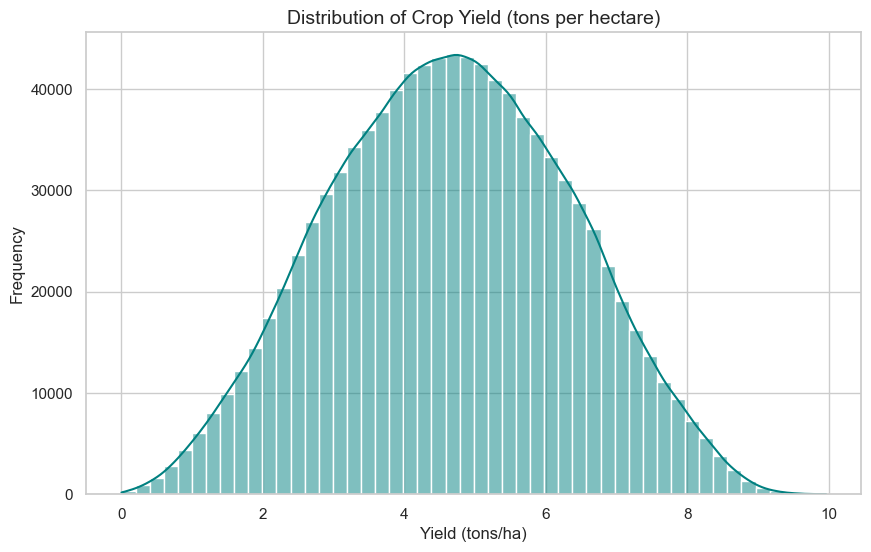

In [15]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Yield_tons_per_hectare'], bins=50, kde=True, color='teal')
plt.title('Distribution of Crop Yield (tons per hectare)', fontsize=14)
plt.xlabel('Yield (tons/ha)')
plt.ylabel('Frequency')
plt.show()

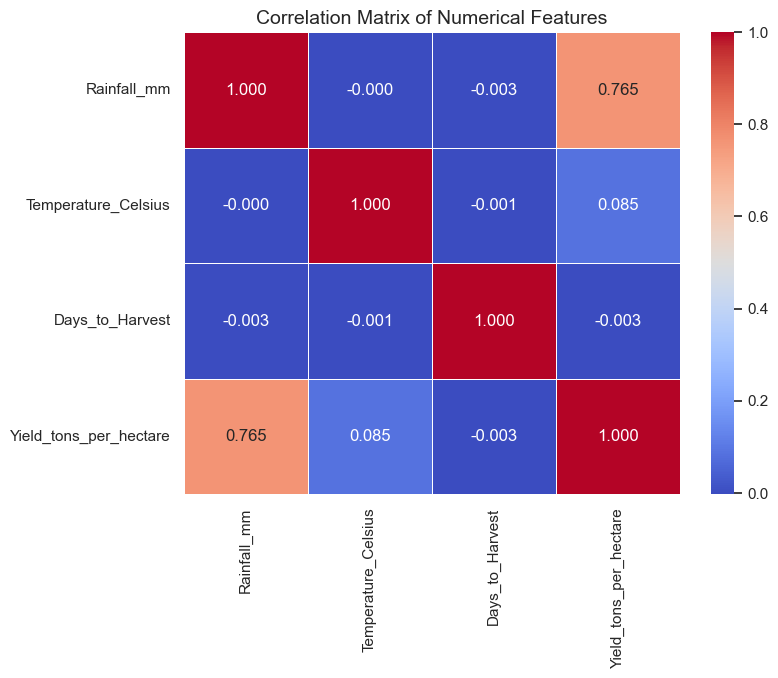

In [17]:
# Isolate numerical columns to find correlations
numerical_cols = df.select_dtypes(include=[np.number])
plt.figure(figsize=(8, 6))
sns.heatmap(numerical_cols.corr(), annot=True, cmap='coolwarm', fmt=".3f", linewidths=0.5)
plt.title('Correlation Matrix of Numerical Features', fontsize=14)
plt.show()

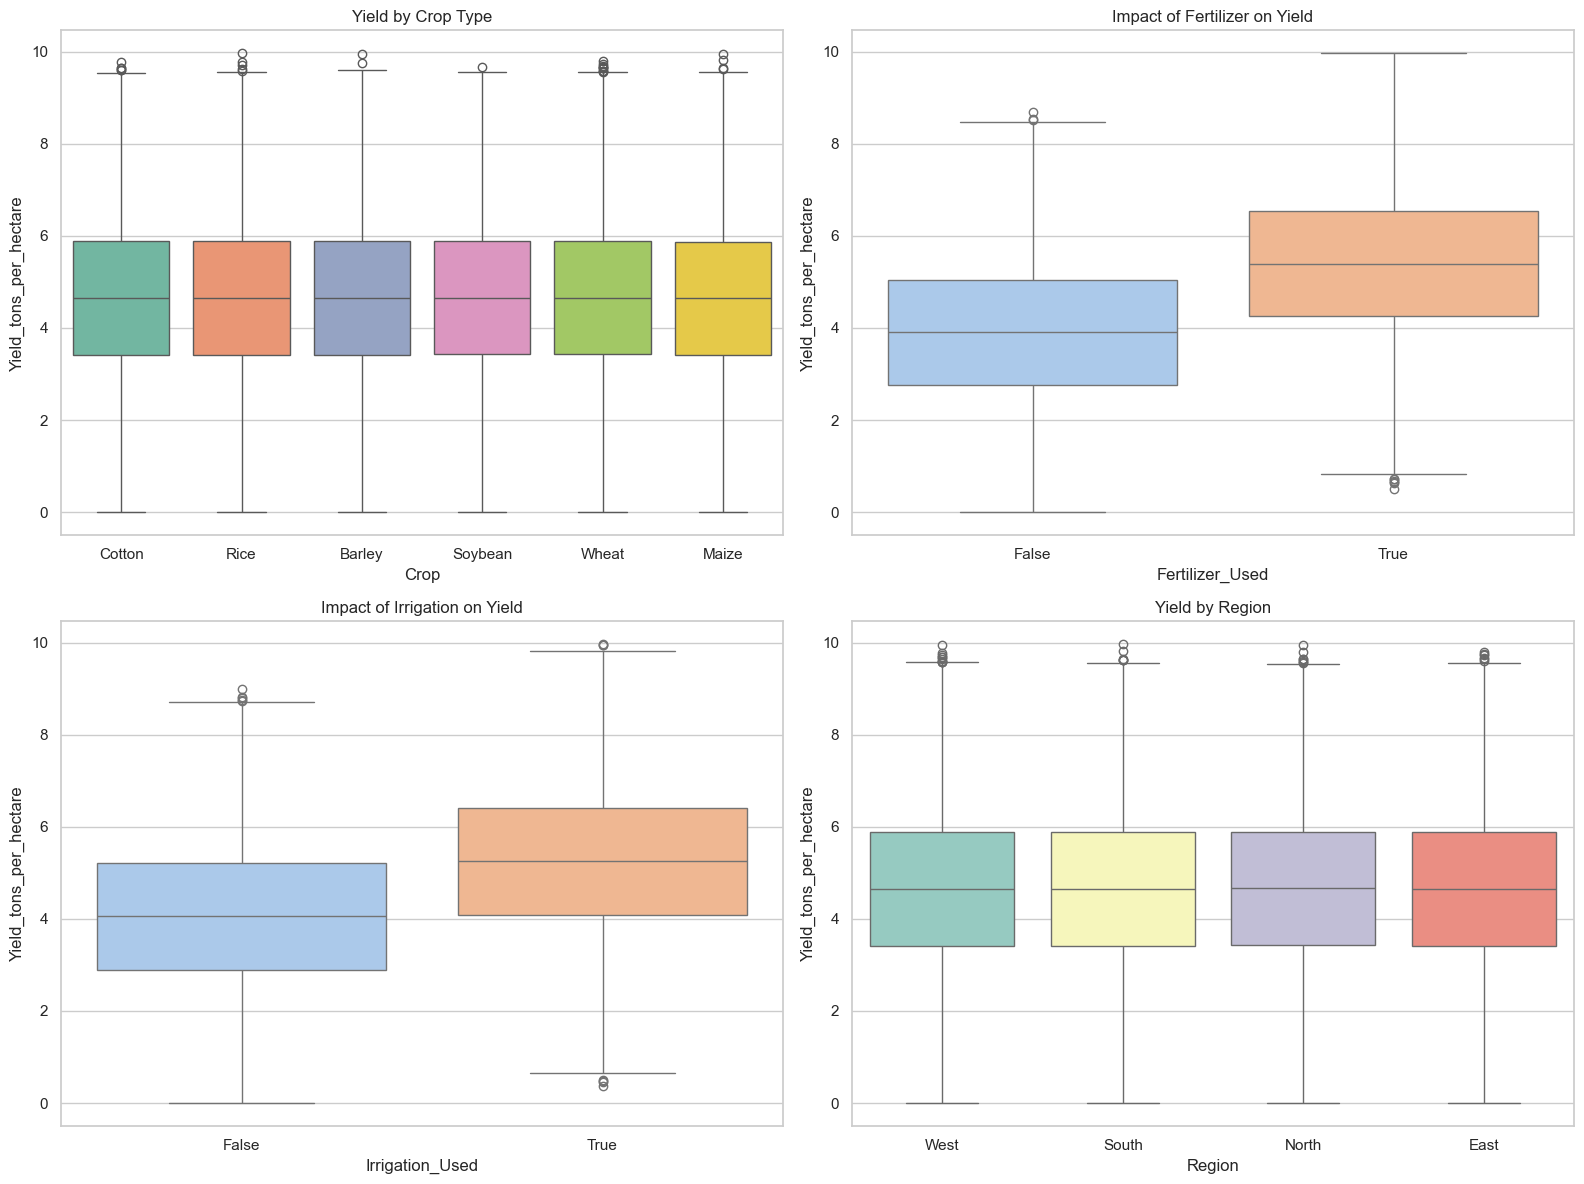

In [21]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Yield by Crop
sns.boxplot(data=df, x='Crop', y='Yield_tons_per_hectare', ax=axes[0, 0], hue='Crop', palette='Set2', legend=False)
axes[0, 0].set_title('Yield by Crop Type')

# Yield by Fertilizer
sns.boxplot(data=df, x='Fertilizer_Used', y='Yield_tons_per_hectare', ax=axes[0, 1], hue='Fertilizer_Used', palette='pastel', legend=False)
axes[0, 1].set_title('Impact of Fertilizer on Yield')

# Yield by Irrigation
sns.boxplot(data=df, x='Irrigation_Used', y='Yield_tons_per_hectare', ax=axes[1, 0], hue='Irrigation_Used', palette='pastel', legend=False)
axes[1, 0].set_title('Impact of Irrigation on Yield')

# Yield by Region
sns.boxplot(data=df, x='Region', y='Yield_tons_per_hectare', ax=axes[1, 1], hue='Region', palette='Set3', legend=False)
axes[1, 1].set_title('Yield by Region')

plt.tight_layout()
plt.show()

# Feature Separation and One-Hot Encoding

In [60]:
# Separate features and target directly from the full cleaned dataframe
X = df.drop(columns=['Yield_tons_per_hectare'])
y = df['Yield_tons_per_hectare']

In [62]:
# One-Hot Encoding via ColumnTransformer
categorical_cols = ['Region', 'Soil_Type', 'Crop', 'Weather_Condition']
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ],
    remainder='passthrough'
)

In [64]:
# Process features and retain column names for SHAP
X_processed = preprocessor.fit_transform(X)
feature_names = preprocessor.get_feature_names_out()

In [66]:
# Creating DataFrame AND casting all columns to float32 to prevent XGBoost type errors and save RAM
X_processed_df = pd.DataFrame(X_processed, columns=feature_names).astype('float32')

In [68]:
# Train-test split on the full 1-million row dataset
X_train, X_test, y_train, y_test = train_test_split(X_processed_df, y, test_size=0.2, random_state=42)

# Model Training and Evalutaion

In [70]:
# Initialize models
models = {
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(n_estimators=100, random_state=42)
}

results = []
trained_models = {}

print("Training and evaluating models...")
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = mean_squared_error(y_test, y_pred) ** 0.5
    r2 = r2_score(y_test, y_pred)
    
    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2})
    trained_models[name] = model

results_df = pd.DataFrame(results)
display(results_df)

Training and evaluating models...


,Model,MAE,RMSE,R2 Score
0,Random Forest,0.410503,0.514509,0.907857
1,XGBoost,0.399532,0.500781,0.912708
2,Gradient Boosting,0.399593,0.500806,0.912699


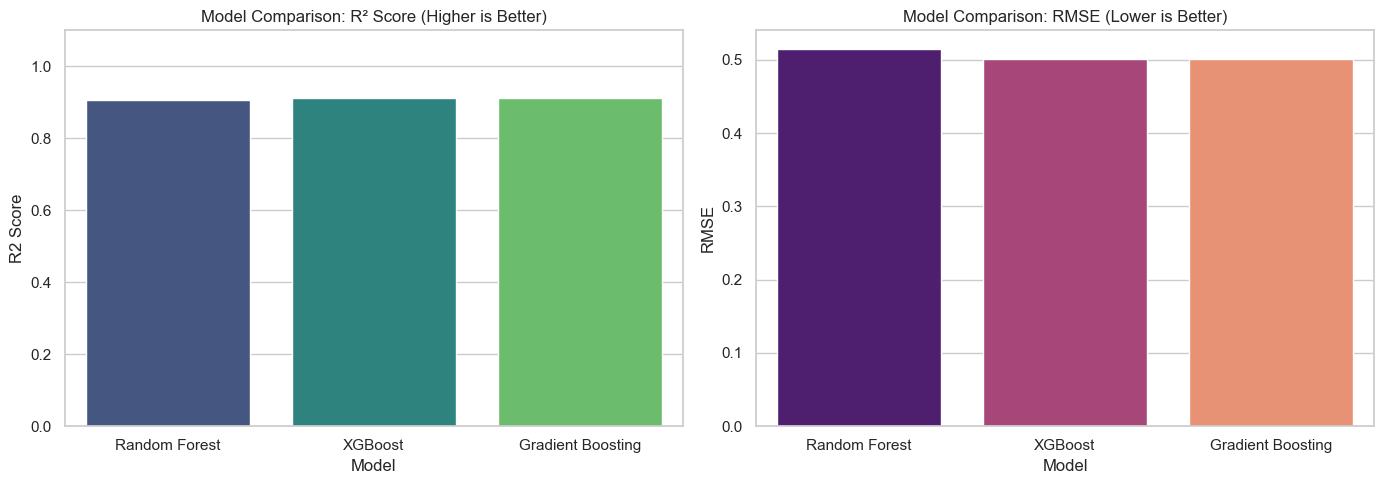

In [72]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot R-squared
sns.barplot(data=results_df, x="Model", y="R2 Score", ax=axes[0], hue="Model", palette="viridis", legend=False)
axes[0].set_title("Model Comparison: R² Score (Higher is Better)")
axes[0].set_ylim(0, 1.1)

# Plot RMSE
sns.barplot(data=results_df, x="Model", y="RMSE", ax=axes[1], hue="Model", palette="magma", legend=False)
axes[1].set_title("Model Comparison: RMSE (Lower is Better)")

plt.tight_layout()
plt.show()

In [74]:
# Automatically selecting the model with the highest R2 score
best_model_name = results_df.loc[results_df['R2 Score'].idxmax(), 'Model']
print(f"The Winning Model is: {best_model_name}")

The Winning Model is: XGBoost


# Final Model Selection and StreamLit Deployment

In [76]:
# final model selection
final_model = trained_models[best_model_name]

# Initializing SHAP explainer using the best model
print("Setting up SHAP Explainer...")
background_data = shap.sample(X_train, 100)
explainer = shap.TreeExplainer(final_model, background_data)

# Saving the necessary artifacts for Streamlit deployment
joblib.dump(final_model, 'best_crop_yield_model.pkl')
joblib.dump(preprocessor, 'preprocessor.pkl')
joblib.dump(explainer, 'shap_explainer.pkl')

print("Success!")

Setting up SHAP Explainer...
Success!
